## Cell 1 — Install Libraries

In [ ]:
import os
os.environ['PYTORCH_ALLOC_CONF'] = 'expandable_segments:True'

!pip install -q unsloth
!pip install -q --no-deps trl peft accelerate bitsandbytes
!pip install -q "transformers>=4.45.0,<5.0.0" "datasets>=2.18.0"
!pip install -q scikit-learn matplotlib seaborn pandas

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.4/71.4 MB 13.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.7/60.7 MB 15.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 506.8/506.8 kB 41.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 915.6/915.6 MB 961.5 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 86.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 706.8/706.8 MB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.3/322.3 MB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 79.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 kB 24.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 924.2/924.2 kB 52.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 58.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

## Cell 2 — Imports

In [ ]:
import os, gc, json, math, random, shutil, torch, torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import bitsandbytes as bnb

from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, confusion_matrix
)
from transformers import (
    DataCollatorWithPadding, get_linear_schedule_with_warmup
)
from peft import PeftModel
from unsloth import FastLanguageModel
from google.colab import drive

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
print('VRAM:', f'{torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB' if torch.cuda.is_available() else 'N/A')

/usr/local/lib/python3.12/dist-packages/unsloth/__init__.py:144: UserWarning: WARNING: Unsloth should be imported before [transformers, peft] to ensure all optimizations are applied. Your code may run slower or encounter memory issues without these optimizations.

Please restructure your imports with 'import unsloth' at the top of your file.
  from ._gpu_init import *


🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
GPU: Tesla T4
VRAM: 15.6 GB


In [ ]:
# ══════════════════════════════════════════════════
# PATHS
# ══════════════════════════════════════════════════
DATA_PATH       = '/content/drive/MyDrive/IT Support Ticket Data.csv'
CHECKPOINT_BASE = '/content/drive/MyDrive/llama32-ticket-cls-v3-singlerun-r8'

# ══════════════════════════════════════════════════
# MODEL (same as V2)
# ══════════════════════════════════════════════════
MODEL_NAME  = 'unsloth/Llama-3.2-3B-bnb-4bit'
MAX_SEQ_LEN = 256

# ══════════════════════════════════════════════════
# DATA SPLIT (same as V2 / Classical ML)
# ══════════════════════════════════════════════════
RANDOM_STATE = 42
TEST_SIZE    = 0.2
VAL_SIZE     = 0.5

# ══════════════════════════════════════════════════
# TRAINING HYPERPARAMETERS (identical to V2)
# ══════════════════════════════════════════════════
BATCH_SIZE              = 2
EVAL_BATCH_SIZE         = 8
GRAD_ACCUM              = 16    # effective batch = 32
MAX_EPOCHS              = 3
EARLY_STOPPING_PATIENCE = 2     # now GLOBAL (no stages)
WEIGHT_DECAY            = 0.01
MAX_GRAD_NORM           = 1.0

# ══════════════════════════════════════════════════
# LORA TARGET MODULES (identical to V2)
# ══════════════════════════════════════════════════
LORA_TARGET_MODULES = [
    'q_proj', 'k_proj', 'v_proj', 'o_proj',
    'gate_proj', 'up_proj', 'down_proj',
]


LORA_CONFIG = {'name': 'LoRA_8', 'r': 8, 'alpha': 16, 'lr': 2e-4, 'dropout': 0.05}

# ══════════════════════════════════════════════════
# CLASSES (identical to V2)
# ══════════════════════════════════════════════════
DEPARTMENTS = [
    'Billing and Payments', 'Customer Service', 'General Inquiry',
    'Human Resources', 'IT Support', 'Product Support',
    'Returns and Exchanges', 'Sales and Pre-Sales',
    'Service Outages and Maintenance', 'Technical Support',
]
LABEL2ID = {d: i for i, d in enumerate(DEPARTMENTS)}
ID2LABEL = {i: d for d, i in LABEL2ID.items()}
NUM_CLASSES = len(DEPARTMENTS)

print('✅ Config loaded (V3 Single-Run)')
print(f'   Model       : {MODEL_NAME}')
print(f'   Strategy    : SINGLE-RUN on full training set')
print(f'   LoRA        : r={LORA_CONFIG["r"]} alpha={LORA_CONFIG["alpha"]} '
      f'(={LORA_CONFIG["alpha"]//LORA_CONFIG["r"]}r) '
      f'dropout={LORA_CONFIG["dropout"]} lr={LORA_CONFIG["lr"]}')
print(f'   Eff. batch  : {BATCH_SIZE} × {GRAD_ACCUM} = {BATCH_SIZE*GRAD_ACCUM}')
print(f'   Max epochs  : {MAX_EPOCHS} | Patience: {EARLY_STOPPING_PATIENCE} (global)')
print(f'   Grad norm   : {MAX_GRAD_NORM}')

✅ Config loaded (V3 Single-Run)
   Model       : unsloth/Llama-3.2-3B-bnb-4bit
   Strategy    : SINGLE-RUN on full training set
   LoRA        : r=8 alpha=16 (=2r) dropout=0.05 lr=0.0002
   Eff. batch  : 2 × 16 = 32
   Max epochs  : 3 | Patience: 2 (global)
   Grad norm   : 1.0


## Cell 4 — Mount Drive & Load Data

In [ ]:
drive.mount('/content/drive')
os.makedirs(CHECKPOINT_BASE, exist_ok=True)

df = pd.read_csv(DATA_PATH, index_col=0)
df = df.dropna(subset=['Body']).reset_index(drop=True)
df = df.drop_duplicates().reset_index(drop=True)   # ← السطر الجديد (نفس الـ classical)

df = df[['Body', 'Department']]
df = df[df['Department'].isin(DEPARTMENTS)].reset_index(drop=True)

print(f'Total samples: {len(df)}')
print('Department distribution:')
print(df['Department'].value_counts())

Mounted at /content/drive
Total samples: 25222
Department distribution:
Department
Technical Support                  7345
Product Support                    4670
Customer Service                   3789
IT Support                         3009
Billing and Payments               2563
Returns and Exchanges              1243
Service Outages and Maintenance    1000
Sales and Pre-Sales                 768
Human Resources                     477
General Inquiry                     358
Name: count, dtype: int64


## Cell 5 — Data Split (No Stages)**Critical:** Same `random_state=42` and `stratify=Department` as V2 → the train/val/test splits are byte-identical. The ONLY difference is we do NOT slice `train_df` into 7 stages.

In [ ]:
# Same split as V2 / Classical ML for fair comparison
train_df, temp_df = train_test_split(
    df, test_size=TEST_SIZE,
    stratify=df['Department'], random_state=RANDOM_STATE
)
val_df, test_df = train_test_split(
    temp_df, test_size=VAL_SIZE,
    stratify=temp_df['Department'], random_state=RANDOM_STATE
)

train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)

print(f'Train : {len(train_df):>6}  (100% — single run)')
print(f'Val   : {len(val_df):>6}')
print(f'Test  : {len(test_df):>6}')
print()
print('Train class distribution:')
print(train_df['Department'].value_counts())

Train :  20177  (100% — single run)
Val   :   2522
Test  :   2523

Train class distribution:
Department
Technical Support                  5876
Product Support                    3736
Customer Service                   3031
IT Support                         2407
Billing and Payments               2050
Returns and Exchanges               994
Service Outages and Maintenance     800
Sales and Pre-Sales                 614
Human Resources                     382
General Inquiry                     287
Name: count, dtype: int64


## Cell 6 — Tokenizer + Dataset + Dynamic Padding (identical to V2)

In [ ]:
# Load tokenizer once
_, tokenizer = FastLanguageModel.from_pretrained(
    model_name=MODEL_NAME,
    max_seq_length=MAX_SEQ_LEN,
    dtype=None,
    load_in_4bit=True,
)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = 'right'   # paper Table 1 + V2


class TicketDataset(Dataset):
    def __init__(self, dataframe, tokenizer, max_len):
        self.texts     = dataframe['Body'].astype(str).tolist()
        self.labels    = [LABEL2ID[d] for d in dataframe['Department'].tolist()]
        self.tokenizer = tokenizer
        self.max_len   = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            max_length=self.max_len,
            truncation=True,
            return_tensors='pt',
        )
        return {
            'input_ids':      enc['input_ids'].squeeze(0),
            'attention_mask': enc['attention_mask'].squeeze(0),
            'labels':         self.labels[idx],
        }


# Dynamic padding — pad only to longest in each batch (paper Table 1)
base_collator = DataCollatorWithPadding(tokenizer=tokenizer, padding='longest')


class TicketCollator:
    def __init__(self, collator):
        self.collator = collator
    def __call__(self, features):
        labels = [f.pop('labels') for f in features]
        batch  = self.collator(features)
        batch['labels'] = torch.tensor(labels, dtype=torch.long)
        return batch


collator = TicketCollator(base_collator)

# Full-training loader (no staging)
train_loader = DataLoader(
    TicketDataset(train_df, tokenizer, MAX_SEQ_LEN),
    batch_size=BATCH_SIZE, shuffle=True, collate_fn=collator,
)
val_loader = DataLoader(
    TicketDataset(val_df, tokenizer, MAX_SEQ_LEN),
    batch_size=EVAL_BATCH_SIZE, shuffle=False, collate_fn=collator,
)
test_loader = DataLoader(
    TicketDataset(test_df, tokenizer, MAX_SEQ_LEN),
    batch_size=EVAL_BATCH_SIZE, shuffle=False, collate_fn=collator,
)

print('✅ Tokenizer + Dynamic padding ready')
print(f'   Train batches : {len(train_loader)}  (batch_size={BATCH_SIZE})')
print(f'   Val batches   : {len(val_loader)}')
print(f'   Test batches  : {len(test_loader)}')
print(f'   Optimizer updates per epoch: {math.ceil(len(train_loader) / GRAD_ACCUM)}')

==((====))==  Unsloth 2026.5.9: Fast Llama patching. Transformers: 4.57.6.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


model.safetensors:   0%|          | 0.00/2.24G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/230 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/459 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.2M [00:00<?, ?B/s]

✅ Tokenizer + Dynamic padding ready
   Train batches : 10089  (batch_size=2)
   Val batches   : 316
   Test batches  : 316
   Optimizer updates per epoch: 631


## Cell 7 — Model: Llama-3.2-3B + rsLoRA + Single Linear Head (identical to V2)

In [ ]:
class LlamaTicketClassifier(nn.Module):
    """
    Embedding-based classification — IDENTICAL to V2.

    - Last non-padding token pooling
    - Single Linear head: hidden_size → num_classes (paper Table 1)
    - head in float32 to avoid NaN loss with 4-bit backbone
    - rsLoRA enabled (use_rslora=True)
    - All 7 linear layers targeted
    """

    def __init__(self, model_name, num_classes, lora_cfg,
                 adapter_path=None, is_trainable=True):
        super().__init__()
        self.lora_cfg = lora_cfg

        base_model, _ = FastLanguageModel.from_pretrained(
            model_name=model_name,
            max_seq_length=MAX_SEQ_LEN,
            dtype=None,
            load_in_4bit=True,
        )

        if adapter_path is None:
            self.backbone = FastLanguageModel.get_peft_model(
                base_model,
                r                          = lora_cfg['r'],
                lora_alpha                 = lora_cfg['alpha'],
                target_modules             = LORA_TARGET_MODULES,
                lora_dropout               = lora_cfg['dropout'],
                bias                       = 'none',
                use_rslora                 = True,
                use_gradient_checkpointing = 'unsloth',
                random_state               = RANDOM_STATE,
            )
            print('Loaded fresh rsLoRA adapters for training.')
        else:
            self.backbone = PeftModel.from_pretrained(
                base_model, adapter_path, is_trainable=is_trainable,
            )
            print(f'Loaded adapters from: {adapter_path}')

        self.backbone.print_trainable_parameters()

        hidden_size = self.backbone.config.hidden_size  # 3072 for Llama-3.2-3B

        # Single Linear head in float32 (paper Table 1)
        self.classifier = nn.Linear(hidden_size, num_classes).float()
        nn.init.xavier_uniform_(self.classifier.weight)
        nn.init.zeros_(self.classifier.bias)
        self.classifier = self.classifier.to(device=self.backbone.device)

        self.loss_fn = nn.CrossEntropyLoss()

        print()
        print('✅ LlamaTicketClassifier ready')
        print(f'   Hidden size : {hidden_size}')
        print(f'   Head        : {hidden_size} → {num_classes}  (single linear)')
        print(f'   rsLoRA      : enabled | alpha={lora_cfg["alpha"]} = {lora_cfg["alpha"]//lora_cfg["r"]}r')
        print(f'   Pooling     : last non-padding token')
        print(f'   Dropout     : {lora_cfg["dropout"]} (LoRA)')

    def forward(self, input_ids, attention_mask, labels=None):
        outputs = self.backbone(
            input_ids=input_ids,
            attention_mask=attention_mask,
            output_hidden_states=True,
        )
        last_hidden  = outputs.hidden_states[-1]
        seq_lengths  = attention_mask.sum(dim=1) - 1
        batch_size   = input_ids.shape[0]
        pooled = last_hidden[
            torch.arange(batch_size, device=input_ids.device),
            seq_lengths,
        ].float()

        logits = self.classifier(pooled)
        loss   = self.loss_fn(logits, labels) if labels is not None else None
        return {'loss': loss, 'logits': logits}


def build_model(lora_cfg, adapter_path=None, is_trainable=True):
    return LlamaTicketClassifier(
        model_name   = MODEL_NAME,
        num_classes  = NUM_CLASSES,
        lora_cfg     = lora_cfg,
        adapter_path = adapter_path,
        is_trainable = is_trainable,
    )


print('✅ Model class defined')

✅ Model class defined


## Cell 8 — Evaluation Function (identical to V2)

In [ ]:
def evaluate(model, loader, split_name='Val', show_plots=True, save_dir=None):
    model.eval()
    device     = next(model.parameters()).device
    all_preds  = []
    all_labels = []

    with torch.no_grad():
        for batch in loader:
            out = model(
                input_ids      = batch['input_ids'].to(device),
                attention_mask = batch['attention_mask'].to(device),
            )
            all_preds.extend(out['logits'].argmax(dim=-1).cpu().numpy())
            all_labels.extend(batch['labels'].numpy())

    acc    = accuracy_score(all_labels, all_preds)
    f1m    = f1_score(all_labels, all_preds, average='macro',    zero_division=0)
    f1w    = f1_score(all_labels, all_preds, average='weighted', zero_division=0)
    f1_pc  = f1_score(all_labels, all_preds, average=None,       zero_division=0)
    cm     = confusion_matrix(all_labels, all_preds)
    report = classification_report(
        all_labels, all_preds, target_names=DEPARTMENTS,
        zero_division=0, output_dict=True
    )

    print('=' * 65)
    print(f'  {split_name}')
    print('=' * 65)
    print(f'  Accuracy    : {acc:.4f}  ({acc*100:.2f}%)')
    print(f'  F1 Macro    : {f1m:.4f}')
    print(f'  F1 Weighted : {f1w:.4f}')
    print()
    print(classification_report(
        all_labels, all_preds, target_names=DEPARTMENTS, zero_division=0
    ))

    if show_plots:
        fig = plt.figure(figsize=(18, 7))
        gs  = gridspec.GridSpec(1, 2, width_ratios=[1.8, 1])

        ax1 = fig.add_subplot(gs[0])
        short = [d[:18] for d in DEPARTMENTS]
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                    xticklabels=short, yticklabels=short, ax=ax1)
        ax1.set_title(f'Confusion Matrix — {split_name}', fontsize=13)
        ax1.set_xlabel('Predicted'); ax1.set_ylabel('True')
        plt.setp(ax1.get_xticklabels(), rotation=45, ha='right', fontsize=8)
        plt.setp(ax1.get_yticklabels(), rotation=0,  fontsize=8)

        ax2 = fig.add_subplot(gs[1])
        sns.barplot(x=f1_pc, y=short, ax=ax2, palette='viridis')
        ax2.set_xlim(0, 1); ax2.set_xlabel('F1-score')
        ax2.set_title('F1 per Class')
        for i, v in enumerate(f1_pc):
            ax2.text(v + 0.01, i, f'{v:.2f}', va='center', fontsize=8)

        plt.tight_layout()
        if save_dir:
            os.makedirs(save_dir, exist_ok=True)
            fp = os.path.join(save_dir, f'{split_name.replace(" ", "_")}.png')
            plt.savefig(fp, dpi=120, bbox_inches='tight')
            print(f'  📊 Saved: {fp}')
        plt.show()
        plt.close(fig)

    return {
        'accuracy': acc, 'f1_macro': f1m, 'f1_weighted': f1w,
        'f1_per_class': f1_pc.tolist(),
        'confusion_matrix': cm.tolist(),
        'classification_report': report,
    }


print('✅ Evaluate function defined')

✅ Evaluate function defined


In [ ]:
def checkpoint_dir(lora_name, tag):
    return os.path.join(CHECKPOINT_BASE, lora_name, tag)

def adapter_dir(lora_name, tag):
    return os.path.join(checkpoint_dir(lora_name, tag), 'lora_adapters')


def save_checkpoint(model, optimizer, scheduler, epoch, lora_name,
                    metrics, best_val_f1, patience_counter, train_history,
                    tag=None, is_best=False):
    tag      = tag or f'epoch{epoch}'
    ckpt_dir = checkpoint_dir(lora_name, tag)
    os.makedirs(ckpt_dir, exist_ok=True)

    model.backbone.save_pretrained(adapter_dir(lora_name, tag))
    torch.save(model.classifier.state_dict(),
               os.path.join(ckpt_dir, 'classifier_head.pt'))

    state = {
        'epoch': epoch, 'lora_name': lora_name,
        'best_val_f1': best_val_f1,
        'patience_counter': patience_counter, 'metrics': metrics,
        'optimizer': optimizer.state_dict(),
        'scheduler': scheduler.state_dict() if scheduler else None,
        'train_history': train_history, 'is_best': is_best, 'tag': tag,
    }
    torch.save(state, os.path.join(ckpt_dir, 'training_state.pt'))

    mj = {
        'epoch': epoch, 'lora_config': lora_name,
        'tag': tag, 'is_best': is_best,
        'accuracy':    round(metrics['accuracy'],    6),
        'f1_macro':    round(metrics['f1_macro'],    6),
        'f1_weighted': round(metrics['f1_weighted'], 6),
        'train_loss':  round(metrics.get('train_loss', 0.0), 6),
        'train_acc':   round(metrics.get('train_acc',  0.0), 6),
        'f1_per_class': {DEPARTMENTS[i]: round(v, 4)
                         for i, v in enumerate(metrics['f1_per_class'])},
    }
    with open(os.path.join(ckpt_dir, 'metrics.json'), 'w') as f:
        json.dump(mj, f, indent=2)

    label = '🏆 BEST' if is_best else '💾'
    print(f'  {label} Checkpoint → {ckpt_dir}')
    print(f'     acc={metrics["accuracy"]:.4f} | F1-macro={metrics["f1_macro"]:.4f}')


def load_checkpoint_state(optimizer, scheduler, lora_name, tag='LAST'):
    ckpt_dir = checkpoint_dir(lora_name, tag)
    if not os.path.exists(ckpt_dir):
        print(f'  ⚠️  Not found: {ckpt_dir}')
        return None
    state = torch.load(os.path.join(ckpt_dir, 'training_state.pt'),
                       map_location='cpu')
    optimizer.load_state_dict(state['optimizer'])
    if scheduler and state.get('scheduler'):
        scheduler.load_state_dict(state['scheduler'])
    print(f'  ✅ Loaded state: ep={state["epoch"]} '
          f'best_f1={state["best_val_f1"]:.4f}')
    return state


def load_classifier_head(model, lora_name, tag='BEST'):
    ckpt_dir = checkpoint_dir(lora_name, tag)
    if not os.path.exists(ckpt_dir):
        print(f'⚠️  Checkpoint not found: {lora_name} @ {tag}')
        return False
    model.classifier.load_state_dict(
        torch.load(os.path.join(ckpt_dir, 'classifier_head.pt'),
                   map_location=model.classifier.weight.device)
    )
    print(f'✅ Loaded classifier head: {ckpt_dir}')
    return True


def list_checkpoints():
    if not os.path.exists(CHECKPOINT_BASE):
        print('No checkpoints directory yet.')
        return
    for lora_name in sorted(os.listdir(CHECKPOINT_BASE)):
        d = os.path.join(CHECKPOINT_BASE, lora_name)
        if not os.path.isdir(d):
            continue
        print(f'\n📁 {lora_name}')
        for tag in sorted(os.listdir(d)):
            tp = os.path.join(d, tag)
            if not os.path.isdir(tp):
                continue
            mf = os.path.join(tp, 'metrics.json')
            if os.path.exists(mf):
                with open(mf) as f:
                    m = json.load(f)
                flag = ' 🏆' if m.get('is_best') else ''
                print(f'   • {tag:<12} ep={m.get("epoch","?")} '
                      f'F1={m.get("f1_macro",0):.4f} '
                      f'acc={m.get("accuracy",0):.4f}{flag}')
            else:
                print(f'   • {tag}')


print('✅ Checkpoint functions defined')

✅ Checkpoint functions defined


In [ ]:
def build_global_scheduler(optimizer):
    """Linear schedule, no warmup (paper Table 1). Same as V2 but total_steps
    is based on full-training single-run, not stages."""
    steps_per_epoch = math.ceil(len(train_loader) / GRAD_ACCUM)
    total_steps     = max(steps_per_epoch * MAX_EPOCHS, 1)

    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=0,
        num_training_steps=total_steps,
    )
    print(f'  Scheduler: {total_steps} total steps '
          f'({steps_per_epoch} per epoch × {MAX_EPOCHS} epochs)')
    return scheduler


def train_single_run(model, optimizer, scheduler, lora_name,
                     start_epoch=1, global_best_f1=0.0,
                     patience_counter=0, train_history=None):
    """
    Single-run training over the full training set.

    Logic mirrors V2 train_one_stage but without the stage loop.
    Early stopping is GLOBAL (across epochs), patience=2.
    """
    device        = next(model.parameters()).device
    train_history = train_history or []

    print()
    print('=' * 72)
    print(f'  SINGLE-RUN TRAINING | {lora_name}')
    print(f'  Train samples: {len(train_df)} | Batches: {len(train_loader)} | '
          f'Max epochs: {MAX_EPOCHS} | Patience: {EARLY_STOPPING_PATIENCE} (global)')
    print(f'  Starting at epoch {start_epoch} | best_f1 so far: {global_best_f1:.4f}')
    print('=' * 72)

    for epoch in range(start_epoch, MAX_EPOCHS + 1):
        model.train()
        total_loss = 0.0
        correct = total = 0
        optimizer.zero_grad()

        for step, batch in enumerate(train_loader, start=1):
            input_ids      = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels         = batch['labels'].to(device)

            out  = model(input_ids=input_ids,
                         attention_mask=attention_mask, labels=labels)
            loss = out['loss'] / GRAD_ACCUM
            loss.backward()

            if (step % GRAD_ACCUM == 0) or (step == len(train_loader)):
                torch.nn.utils.clip_grad_norm_(
                    [p for p in model.parameters() if p.requires_grad],
                    MAX_GRAD_NORM,
                )
                optimizer.step()
                scheduler.step()
                optimizer.zero_grad()

            total_loss += out['loss'].item()
            preds   = out['logits'].argmax(dim=-1)
            correct += (preds == labels).sum().item()
            total   += labels.size(0)

            # Log every 500 steps (bigger run than V2 stage)
            if step % 500 == 0 or step == len(train_loader):
                cur_lr = scheduler.get_last_lr()[0]
                print(f'   Ep{epoch} | Step {step:>5}/{len(train_loader)} | '
                      f'Loss:{total_loss/step:.4f} | Acc:{correct/total:.4f} | '
                      f'LR:{cur_lr:.2e}')

        train_acc = correct / total
        avg_loss  = total_loss / len(train_loader)
        print(f'\n  ── Ep{epoch} done | Loss={avg_loss:.4f} | '
              f'TrainAcc={train_acc:.4f}')

        # Validate
        val_m = evaluate(model, val_loader,
                         split_name=f'Val Ep{epoch}',
                         show_plots=False)
        val_m['train_acc']  = train_acc
        val_m['train_loss'] = avg_loss

        train_history.append({
            'epoch': epoch,
            'train_loss': avg_loss, 'train_acc': train_acc,
            'val_accuracy': val_m['accuracy'],
            'val_f1_macro': val_m['f1_macro'],
            'val_f1_weighted': val_m['f1_weighted'],
        })

        # Save per-epoch + LAST
        for tag in [f'epoch{epoch}', 'LAST']:
            save_checkpoint(model, optimizer, scheduler,
                            epoch, lora_name,
                            val_m, global_best_f1,
                            patience_counter, train_history,
                            tag=tag, is_best=False)

        # Update BEST
        if val_m['f1_macro'] > global_best_f1:
            global_best_f1   = val_m['f1_macro']
            patience_counter = 0
            save_checkpoint(model, optimizer, scheduler,
                            epoch, lora_name,
                            val_m, global_best_f1,
                            patience_counter, train_history,
                            tag='BEST', is_best=True)
            print(f'  🏆 New BEST F1: {global_best_f1:.4f}')
        else:
            patience_counter += 1
            print(f'  ⏸  No improvement. '
                  f'patience={patience_counter}/{EARLY_STOPPING_PATIENCE}')
            if patience_counter >= EARLY_STOPPING_PATIENCE:
                print(f'  ⛔ Early stop at epoch {epoch}')
                break

    # Final eval plot on val
    evaluate(model, val_loader,
             split_name='Final Val (Single-Run)',
             show_plots=True,
             save_dir=os.path.join(CHECKPOINT_BASE, lora_name))

    return global_best_f1, train_history, patience_counter


print('✅ Single-run training loop defined')

✅ Single-run training loop defined


old training with data leakage


########################################################################
  V3 SINGLE-RUN EXPERIMENT: LoRA_r16
  r=16 | alpha=32 (=2r) | lr=0.0002 | dropout=0.05
  Full training set: 23720 samples (no staging)
########################################################################
==((====))==  Unsloth 2026.4.6: Fast Llama patching. Transformers: 4.57.6.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Unsloth: Dropout = 0 is supported for fast patching. You are using dropout = 0.05.
Unsloth will patch all other layers, except LoRA matrices, causing a performance hit.
Unsloth 2026.4.6 patched 28 layers with 0 QKV layers, 0 O layers and 0 MLP layers.


Loaded fresh rsLoRA adapters for training.
trainable params: 24,313,856 || all params: 3,237,063,680 || trainable%: 0.7511

✅ LlamaTicketClassifier ready
   Hidden size : 3072
   Head        : 3072 → 10  (single linear)
   rsLoRA      : enabled | alpha=32 = 2r
   Pooling     : last non-padding token
   Dropout     : 0.05 (LoRA)
  Scheduler: 2226 total steps (742 per epoch × 3 epochs)

  SINGLE-RUN TRAINING | LoRA_r16
  Train samples: 23720 | Batches: 11860 | Max epochs: 3 | Patience: 2 (global)
  Starting at epoch 1 | best_f1 so far: 0.0000
   Ep1 | Step   500/11860 | Loss:2.4324 | Acc:0.2410 | LR:1.97e-04
   Ep1 | Step  1000/11860 | Loss:2.1674 | Acc:0.2920 | LR:1.94e-04
   Ep1 | Step  1500/11860 | Loss:2.0544 | Acc:0.3080 | LR:1.92e-04
   Ep1 | Step  2000/11860 | Loss:2.0024 | Acc:0.3150 | LR:1.89e-04
   Ep1 | Step  2500/11860 | Loss:1.9476 | Acc:0.3242 | LR:1.86e-04
   Ep1 | Step  3000/11860 | Loss:1.9070 | Acc:0.3338 | LR:1.83e-04
   Ep1 | Step  3500/11860 | Loss:1.8832 | Acc:0.337

/tmp/ipykernel_2708/2135555504.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=f1_pc, y=short, ax=ax2, palette='viridis')


  📊 Saved: /content/drive/MyDrive/llama32-ticket-cls-v3-singlerun/LoRA_r16/Final_Val_(Single-Run).png


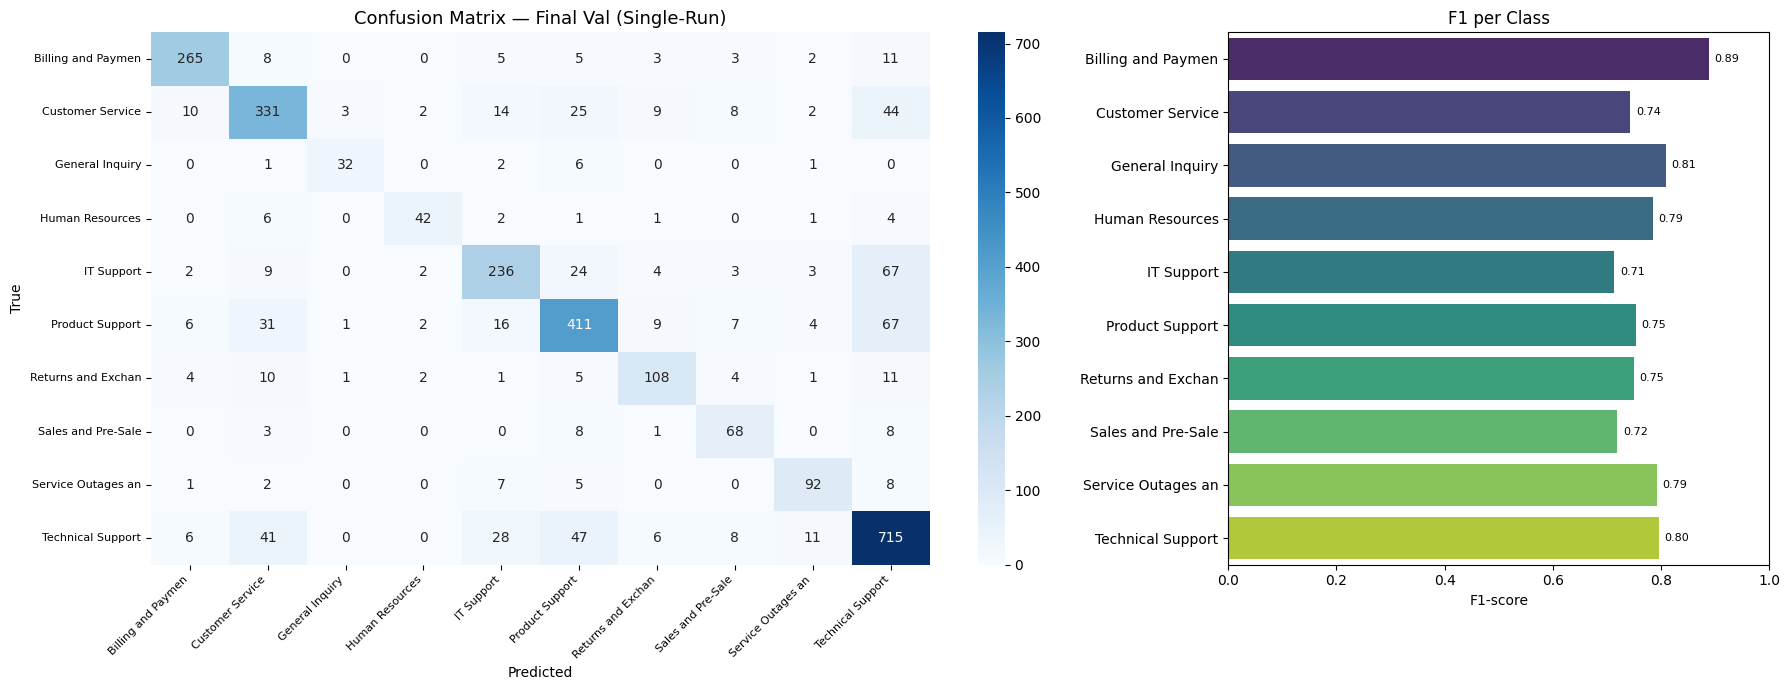


  TRAINING COMPLETE — LoRA_r16 (V3 Single-Run)
  Best Val F1-Macro : 0.7754
  Epochs completed  : 3/3


In [ ]:
# ══════════════════════════════════════════════════
# Fresh start: LoRA_r16 single-run
# ══════════════════════════════════════════════════
gc.collect()
torch.cuda.empty_cache() if torch.cuda.is_available() else None

cfg       = LORA_CONFIG
lora_name = cfg['name']

print()
print('#' * 72)
print(f'  V3 SINGLE-RUN EXPERIMENT: {lora_name}')
print(f'  r={cfg["r"]} | alpha={cfg["alpha"]} (={cfg["alpha"]//cfg["r"]}r) | '
      f'lr={cfg["lr"]} | dropout={cfg["dropout"]}')
print(f'  Full training set: {len(train_df)} samples (no staging)')
print('#' * 72)

model     = build_model(cfg)
trainable = [p for p in model.parameters() if p.requires_grad]

# AdamW8bit — identical to V2
optimizer = bnb.optim.AdamW8bit(
    trainable,
    lr           = cfg['lr'],
    weight_decay = WEIGHT_DECAY,
)

# Global linear scheduler (no warmup) — paper Table 1
scheduler = build_global_scheduler(optimizer)

# Train
best_val_f1, train_history, _ = train_single_run(
    model, optimizer, scheduler, lora_name,
    start_epoch=1, global_best_f1=0.0,
)

# Persist history
summary_dir = os.path.join(CHECKPOINT_BASE, lora_name)
os.makedirs(summary_dir, exist_ok=True)
with open(os.path.join(summary_dir, 'training_history.json'), 'w') as f:
    json.dump(train_history, f, indent=2, default=str)

summary = {
    'config':            lora_name,
    'strategy':          'single_run_full_dataset',
    'r':                 cfg['r'],
    'alpha':             cfg['alpha'],
    'train_samples':     len(train_df),
    'max_epochs':        MAX_EPOCHS,
    'epochs_completed':  len(train_history),
    'best_val_f1_macro': best_val_f1,
}
with open(os.path.join(summary_dir, 'training_summary.json'), 'w') as f:
    json.dump(summary, f, indent=2, default=str)

print()
print('=' * 72)
print(f'  TRAINING COMPLETE — {lora_name} (V3 Single-Run)')
print(f'  Best Val F1-Macro : {best_val_f1:.4f}')
print(f'  Epochs completed  : {len(train_history)}/{MAX_EPOCHS}')
print('=' * 72)

⏱️  Training started at : 2026-04-17 23:56:41
🖥️  GPU memory baseline : 2.27 GB
💾 CPU memory baseline  : 2.84 GB

########################################################################
  V3_r8 SINGLE-RUN EXPERIMENT: LoRA_r8
  r=8 | alpha=16 (=2r) | lr=0.0002 | dropout=0.05
  Full training set: 23720 samples (no staging)
  Paper reference  : Llama-3.2-3B r=8 → F1=0.860 (Yousefiramandi & Cooney 2025)
########################################################################
==((====))==  Unsloth 2026.4.6: Fast Llama patching. Transformers: 4.57.6.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Unsloth: Dropout = 0 is supported for fast patching. You are using dropout = 0.05.
Unsloth will patch all other layers, except LoRA matrices, causing a performance hit.
Unsloth 2026.4.6 patched 28 layers with 0 QKV layers, 0 O layers and 0 MLP layers.


Loaded fresh rsLoRA adapters for training.
trainable params: 12,156,928 || all params: 3,224,906,752 || trainable%: 0.3770

✅ LlamaTicketClassifier ready
   Hidden size : 3072
   Head        : 3072 → 10  (single linear)
   rsLoRA      : enabled | alpha=16 = 2r
   Pooling     : last non-padding token
   Dropout     : 0.05 (LoRA)

  Trainable parameters: 12,187,658 (12.2M)
  Scheduler: 2226 total steps (742 per epoch × 3 epochs)

  SINGLE-RUN TRAINING | LoRA_r8
  Train samples: 23720 | Batches: 11860 | Max epochs: 3 | Patience: 2 (global)
  Starting at epoch 1 | best_f1 so far: 0.0000
   Ep1 | Step   500/11860 | Loss:2.4030 | Acc:0.2310 | LR:1.97e-04
   Ep1 | Step  1000/11860 | Loss:2.1815 | Acc:0.2820 | LR:1.94e-04
   Ep1 | Step  1500/11860 | Loss:2.0611 | Acc:0.3057 | LR:1.92e-04
   Ep1 | Step  2000/11860 | Loss:1.9969 | Acc:0.3142 | LR:1.89e-04
   Ep1 | Step  2500/11860 | Loss:1.9427 | Acc:0.3318 | LR:1.86e-04
   Ep1 | Step  3000/11860 | Loss:1.9058 | Acc:0.3403 | LR:1.83e-04
   Ep1 |

/tmp/ipykernel_16172/2135555504.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=f1_pc, y=short, ax=ax2, palette='viridis')


  📊 Saved: /content/drive/MyDrive/llama32-ticket-cls-v3-singlerun-r8/LoRA_r8/Final_Val_(Single-Run).png


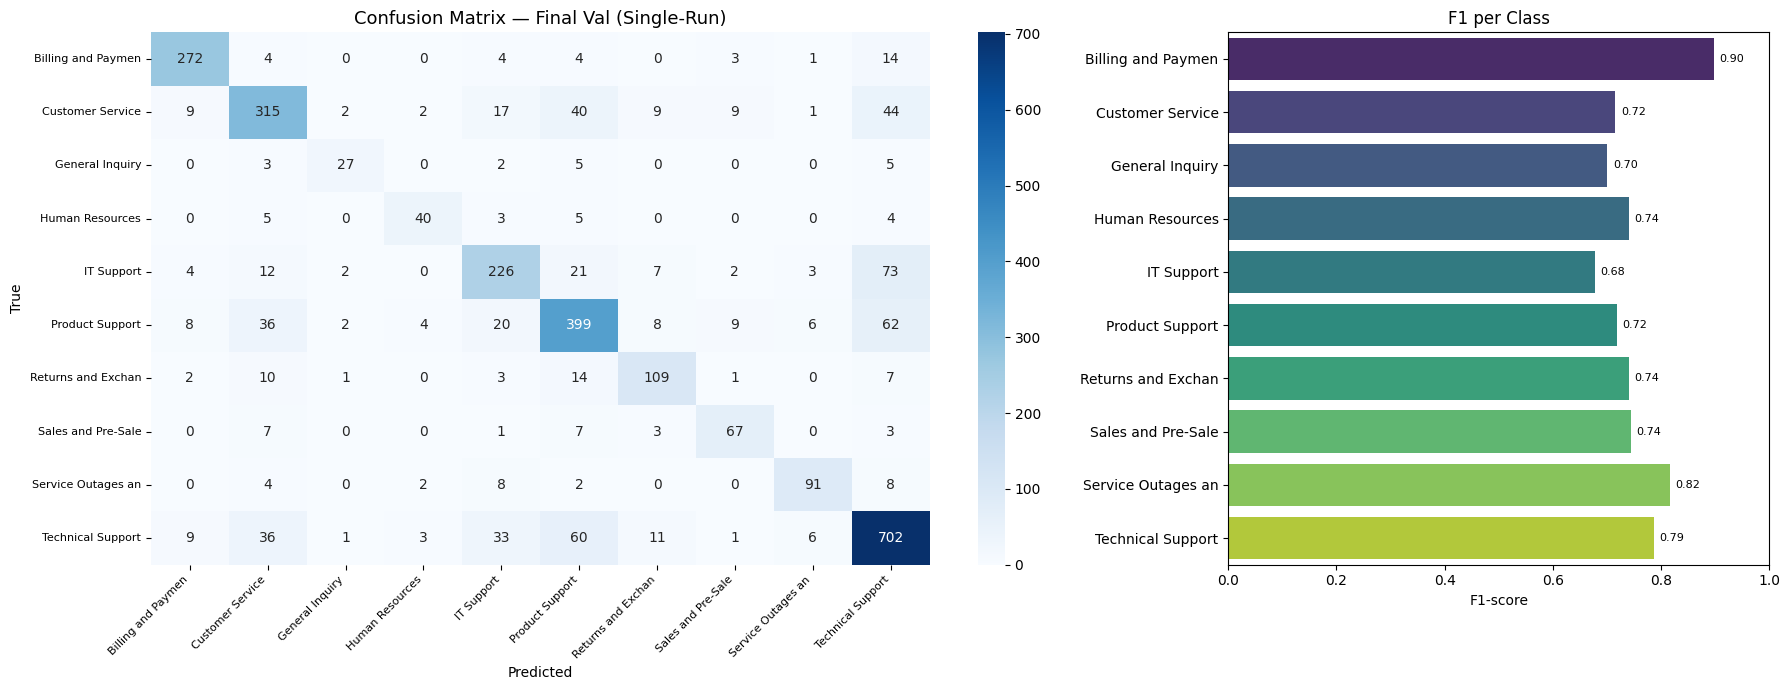


  TRAINING COMPLETE — LoRA_r8 (V3 Single-Run)
  Best Val F1-Macro : 0.7541
  Epochs completed  : 3/3
  Trainable params  : 12,187,658 (12.2M)

  ⏱️  TIME INVESTMENT
  ────────────────────────────────────────────────────────────
  Started           : 2026-04-17 23:56:41
  Finished          : 2026-04-18 05:46:32
  Total duration    : 5h 49m 51s  (20991 seconds)
  Average per epoch : 116.6 minutes
  Throughput        : 3.39 samples/sec

  🖥️  COMPUTE EFFORT
  ────────────────────────────────────────────────────────────
  GPU memory peak   : 5.79 GB / 14.5 GB (T4)
  GPU utilization   : 39.9%
  CPU memory delta  : +0.46 GB during training

  💾 Artifacts saved in: /content/drive/MyDrive/llama32-ticket-cls-v3-singlerun-r8/LoRA_r8
     • training_history.json  (per-epoch metrics)
     • training_summary.json  (overall summary)
     • timing.json            (time + compute tracking)


In [ ]:
# ══════════════════════════════════════════════════════════════════════
#  V3_r8 SINGLE-RUN EXPERIMENT — LoRA rank=8 (paper-best config)
# ──────────────────────────────────────────────────────────────────────


import time
import psutil
from datetime import datetime

# ── TIMING & RESOURCE TRACKING START
train_start      = time.time()
train_start_str  = datetime.now().strftime('%Y-%m-%d %H:%M:%S')

# Initial GPU memory snapshot
if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()
    gpu_mem_start = torch.cuda.memory_allocated() / 1e9
else:
    gpu_mem_start = 0

# Initial CPU memory
cpu_mem_start = psutil.Process().memory_info().rss / 1e9

print(f'⏱️  Training started at : {train_start_str}')
print(f'🖥️  GPU memory baseline : {gpu_mem_start:.2f} GB')
print(f'💾 CPU memory baseline  : {cpu_mem_start:.2f} GB')
print()

# ── Clear VRAM before loading
gc.collect()
torch.cuda.empty_cache() if torch.cuda.is_available() else None

cfg       = LORA_CONFIG
lora_name = cfg['name']

print('#' * 72)
print(f'  V3_r8 SINGLE-RUN EXPERIMENT: {lora_name}')
print(f'  r={cfg["r"]} | alpha={cfg["alpha"]} (={cfg["alpha"]//cfg["r"]}r) | '
      f'lr={cfg["lr"]} | dropout={cfg["dropout"]}')
print(f'  Full training set: {len(train_df)} samples (no staging)')
print(f'  Paper reference  : Llama-3.2-3B r=8 → F1=0.860 (Yousefiramandi & Cooney 2025)')
print('#' * 72)

# ── Build model (this loads the 4-bit base + fresh LoRA adapters)
model     = build_model(cfg)
trainable = [p for p in model.parameters() if p.requires_grad]

# Count trainable parameters for the record
n_trainable = sum(p.numel() for p in trainable)
print(f'\n  Trainable parameters: {n_trainable:,} ({n_trainable/1e6:.1f}M)')

# ── AdamW8bit optimizer (identical to V3 r=16 and V2 — paper Table 1)
optimizer = bnb.optim.AdamW8bit(
    trainable,
    lr           = cfg['lr'],
    weight_decay = WEIGHT_DECAY,
)

# ── Global linear scheduler (no warmup) — paper Table 1
scheduler = build_global_scheduler(optimizer)

# ══════════════════════════════════════════════════════════════════════
# TRAINING EXECUTION
# ══════════════════════════════════════════════════════════════════════
best_val_f1, train_history, _ = train_single_run(
    model, optimizer, scheduler, lora_name,
    start_epoch=1, global_best_f1=0.0,
)

# ══════════════════════════════════════════════════════════════════════
# TIMING & RESOURCE TRACKING END
# ══════════════════════════════════════════════════════════════════════
train_end      = time.time()
train_end_str  = datetime.now().strftime('%Y-%m-%d %H:%M:%S')
total_seconds  = train_end - train_start

# Final resource usage
if torch.cuda.is_available():
    gpu_mem_peak = torch.cuda.max_memory_allocated() / 1e9
    gpu_mem_end  = torch.cuda.memory_allocated() / 1e9
else:
    gpu_mem_peak = gpu_mem_end = 0

cpu_mem_end = psutil.Process().memory_info().rss / 1e9

# Time breakdown
hours   = int(total_seconds // 3600)
minutes = int((total_seconds % 3600) // 60)
seconds = int(total_seconds % 60)

# Compute efficiency metrics
epochs_done        = len(train_history)
avg_sec_per_epoch  = total_seconds / epochs_done if epochs_done else 0
samples_per_sec    = (len(train_df) * epochs_done) / total_seconds if total_seconds else 0

# ── Persist training history + summary (same as before, for consistency with r=16)
summary_dir = os.path.join(CHECKPOINT_BASE, lora_name)
os.makedirs(summary_dir, exist_ok=True)
with open(os.path.join(summary_dir, 'training_history.json'), 'w') as f:
    json.dump(train_history, f, indent=2, default=str)

summary = {
    'config':            lora_name,
    'strategy':          'single_run_full_dataset',
    'r':                 cfg['r'],
    'alpha':             cfg['alpha'],
    'trainable_params':  n_trainable,
    'train_samples':     len(train_df),
    'max_epochs':        MAX_EPOCHS,
    'epochs_completed':  epochs_done,
    'best_val_f1_macro': best_val_f1,
}
with open(os.path.join(summary_dir, 'training_summary.json'), 'w') as f:
    json.dump(summary, f, indent=2, default=str)

# ── Save timing & resource usage (NEW — for thesis comparison table)
timing_data = {
    'lora_config':        lora_name,
    'r':                  cfg['r'],
    'alpha':              cfg['alpha'],
    'trainable_params':   n_trainable,
    'trainable_params_M': round(n_trainable / 1e6, 2),
    'started_at':         train_start_str,
    'finished_at':        train_end_str,
    'total_seconds':      round(total_seconds, 2),
    'duration_str':       f'{hours}h {minutes}m {seconds}s',
    'epochs_completed':   epochs_done,
    'max_epochs':         MAX_EPOCHS,
    'avg_sec_per_epoch':  round(avg_sec_per_epoch, 2),
    'avg_minutes_per_epoch': round(avg_sec_per_epoch / 60, 2),
    'samples_per_second': round(samples_per_sec, 2),
    'train_samples':      len(train_df),
    'best_val_f1':        round(best_val_f1, 4),
    'resources': {
        'gpu_memory_peak_gb': round(gpu_mem_peak, 2),
        'gpu_memory_end_gb':  round(gpu_mem_end, 2),
        'cpu_memory_start_gb':round(cpu_mem_start, 2),
        'cpu_memory_end_gb':  round(cpu_mem_end, 2),
    },
}
with open(os.path.join(summary_dir, 'timing.json'), 'w') as f:
    json.dump(timing_data, f, indent=2)

# ══════════════════════════════════════════════════════════════════════
# FINAL REPORT
# ══════════════════════════════════════════════════════════════════════
print()
print('=' * 72)
print(f'  TRAINING COMPLETE — {lora_name} (V3 Single-Run)')
print('=' * 72)
print(f'  Best Val F1-Macro : {best_val_f1:.4f}')
print(f'  Epochs completed  : {epochs_done}/{MAX_EPOCHS}')
print(f'  Trainable params  : {n_trainable:,} ({n_trainable/1e6:.1f}M)')
print()
print('  ⏱️  TIME INVESTMENT')
print('  ' + '─' * 60)
print(f'  Started           : {train_start_str}')
print(f'  Finished          : {train_end_str}')
print(f'  Total duration    : {hours}h {minutes}m {seconds}s  ({total_seconds:.0f} seconds)')
print(f'  Average per epoch : {avg_sec_per_epoch/60:.1f} minutes')
print(f'  Throughput        : {samples_per_sec:.2f} samples/sec')
print()
print('  🖥️  COMPUTE EFFORT')
print('  ' + '─' * 60)
print(f'  GPU memory peak   : {gpu_mem_peak:.2f} GB / 14.5 GB (T4)')
print(f'  GPU utilization   : {(gpu_mem_peak/14.5)*100:.1f}%')
print(f'  CPU memory delta  : +{cpu_mem_end - cpu_mem_start:.2f} GB during training')
print()
print(f'  💾 Artifacts saved in: {summary_dir}')
print(f'     • training_history.json  (per-epoch metrics)')
print(f'     • training_summary.json  (overall summary)')
print(f'     • timing.json            (time + compute tracking)')
print('=' * 72)

old test wirh data lekage

🏆 Loading BEST checkpoint from /content/drive/MyDrive/llama32-ticket-cls-v3-singlerun/LoRA_r16/BEST
==((====))==  Unsloth 2026.5.2: Fast Llama patching. Transformers: 4.57.6.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Loaded adapters from: /content/drive/MyDrive/llama32-ticket-cls-v3-singlerun/LoRA_r16/BEST/lora_adapters
trainable params: 0 || all params: 3,237,063,680 || trainable%: 0.0000

✅ LlamaTicketClassifier ready
   Hidden size : 3072
   Head        : 3072 → 10  (single linear)
   rsLoRA      : enabled | alpha=32 = 2r
   Pooling     : last non-padding token
   Dropout     : 0.05 (LoRA)
✅ Loaded classifier head: /content/drive/MyDrive/llama32-ticket-cl

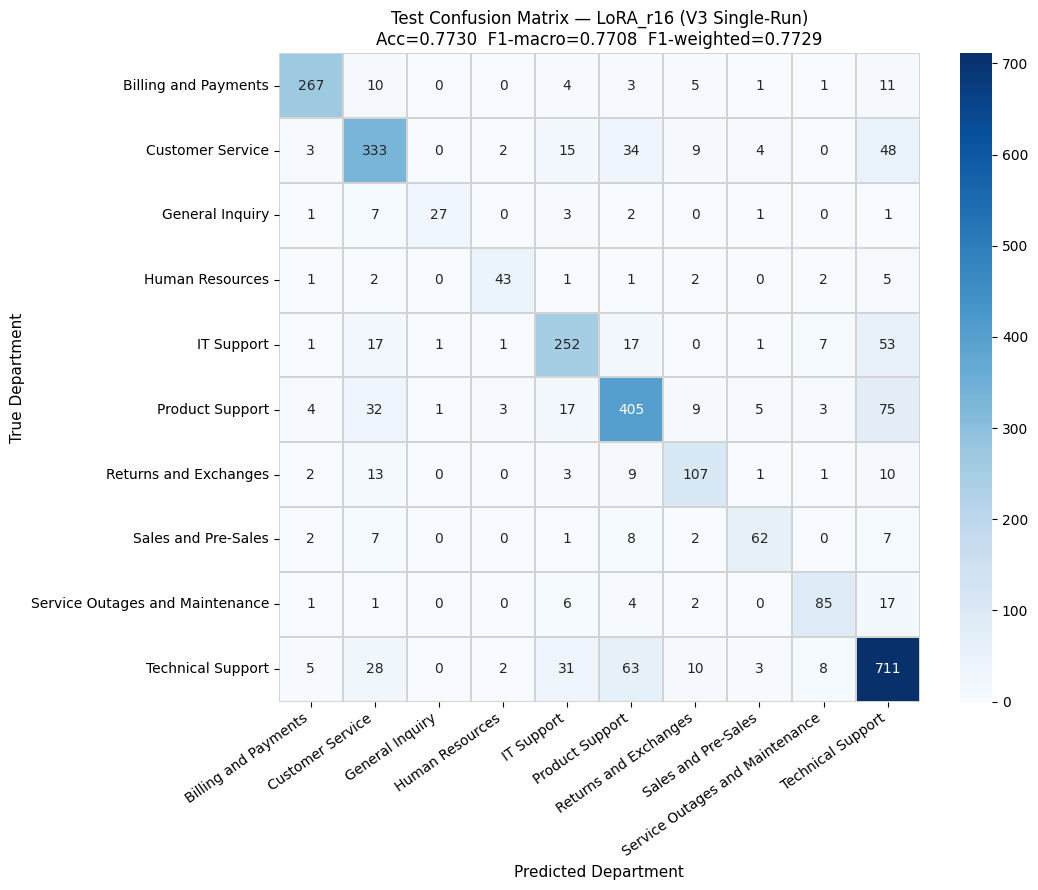


💾 Saved:
   • /content/drive/MyDrive/llama32-ticket-cls-v3-singlerun/LoRA_r16/final_test/test_metrics.json
   • /content/drive/MyDrive/llama32-ticket-cls-v3-singlerun/LoRA_r16/final_test/test_confusion_matrix.png


In [ ]:
# ════════════════════════════════════════════════════════════════════════
# FINAL TEST EVALUATION — LoRA_r16 (V3 Single-Run)
# Loads BEST checkpoint → evaluates on held-out test set → saves CM + JSON
# ════════════════════════════════════════════════════════════════════════
import gc, json, os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, confusion_matrix
)

# ── Make sure CHECKPOINT_BASE points to r=16 path
CHECKPOINT_BASE = '/content/drive/MyDrive/llama32-ticket-cls-v3-singlerun'

# ── LoRA config for r=16 (override Cell 9 if needed)
LORA_CONFIG = {'name': 'LoRA_r16', 'r': 16, 'alpha': 32, 'lr': 2e-4, 'dropout': 0.05}

cfg       = LORA_CONFIG
lora_name = cfg['name']

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

best_dir = os.path.join(CHECKPOINT_BASE, lora_name, 'BEST')
if not os.path.exists(best_dir):
    raise RuntimeError(f'No BEST checkpoint at {best_dir}.')

print(f'🏆 Loading BEST checkpoint from {best_dir}')

# Build model from BEST adapter (frozen — eval only)
test_model = build_model(
    cfg,
    adapter_path=os.path.join(best_dir, 'lora_adapters'),
    is_trainable=False,
)
load_classifier_head(test_model, lora_name, tag='BEST')
test_model.eval()

# ── Run inference manually so we keep predictions + labels for CM
all_preds, all_labels = [], []
device = next(test_model.parameters()).device

with torch.no_grad():
    for batch in test_loader:
        input_ids      = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels         = batch['labels'].to(device)
        out    = test_model(input_ids=input_ids, attention_mask=attention_mask)
        logits = out['logits'] if isinstance(out, dict) else out
        preds  = logits.argmax(dim=-1)
        all_preds.extend(preds.cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

# ── Compute metrics
acc   = accuracy_score(all_labels, all_preds)
f1m   = f1_score(all_labels, all_preds, average='macro')
f1w   = f1_score(all_labels, all_preds, average='weighted')
cm    = confusion_matrix(all_labels, all_preds)
report_str  = classification_report(
    all_labels, all_preds,
    target_names=DEPARTMENTS, digits=4, zero_division=0,
)
report_dict = classification_report(
    all_labels, all_preds,
    target_names=DEPARTMENTS, digits=4, zero_division=0, output_dict=True,
)

print('\n' + '=' * 72)
print(f'  FINAL TEST RESULT — {lora_name} (V3 Single-Run)')
print('=' * 72)
print(f'  Accuracy    : {acc:.4f}  ({acc*100:.2f}%)')
print(f'  F1-Macro    : {f1m:.4f}')
print(f'  F1-Weighted : {f1w:.4f}')
print(f'  Test size   : {len(all_labels)}')
print('=' * 72)
print('\nClassification report:\n')
print(report_str)

# ── Save artifacts
final_dir = os.path.join(CHECKPOINT_BASE, lora_name, 'final_test')
os.makedirs(final_dir, exist_ok=True)

# 1) Numbers as JSON
out_json = {
    'config'         : lora_name,
    'strategy'       : 'single_run_full_dataset',
    'test_size'      : len(all_labels),
    'test_accuracy'  : round(float(acc), 6),
    'test_f1_macro'  : round(float(f1m), 6),
    'test_f1_weighted': round(float(f1w), 6),
    'classification_report': report_dict,
    'confusion_matrix': cm.tolist(),
    'class_names'    : DEPARTMENTS,
}
with open(os.path.join(final_dir, 'test_metrics.json'), 'w') as f:
    json.dump(out_json, f, indent=2)

# 2) Confusion matrix PNG
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=DEPARTMENTS, yticklabels=DEPARTMENTS,
    cbar=True, ax=ax, square=False, linewidths=0.3, linecolor='lightgray',
)
ax.set_xlabel('Predicted Department', fontsize=11)
ax.set_ylabel('True Department', fontsize=11)
ax.set_title(f'Test Confusion Matrix — {lora_name} (V3 Single-Run)\n'
             f'Acc={acc:.4f}  F1-macro={f1m:.4f}  F1-weighted={f1w:.4f}',
             fontsize=12)
plt.xticks(rotation=35, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
cm_path = os.path.join(final_dir, 'test_confusion_matrix.png')
plt.savefig(cm_path, dpi=150, bbox_inches='tight')
plt.show()
plt.close()

print(f'\n💾 Saved:')
print(f'   • {os.path.join(final_dir, "test_metrics.json")}')
print(f'   • {cm_path}')

# ── Free memory
del test_model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

old test r 8 with data lekage

🏆 Loading BEST checkpoint from /content/drive/MyDrive/llama32-ticket-cls-v3-singlerun-r8/LoRA_r8/BEST
==((====))==  Unsloth 2026.5.2: Fast Llama patching. Transformers: 4.57.6.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Loaded adapters from: /content/drive/MyDrive/llama32-ticket-cls-v3-singlerun-r8/LoRA_r8/BEST/lora_adapters
trainable params: 0 || all params: 3,224,906,752 || trainable%: 0.0000

✅ LlamaTicketClassifier ready
   Hidden size : 3072
   Head        : 3072 → 10  (single linear)
   rsLoRA      : enabled | alpha=16 = 2r
   Pooling     : last non-padding token
   Dropout     : 0.05 (LoRA)
✅ Loaded classifier head: /content/drive/MyDrive/llama32-ticke

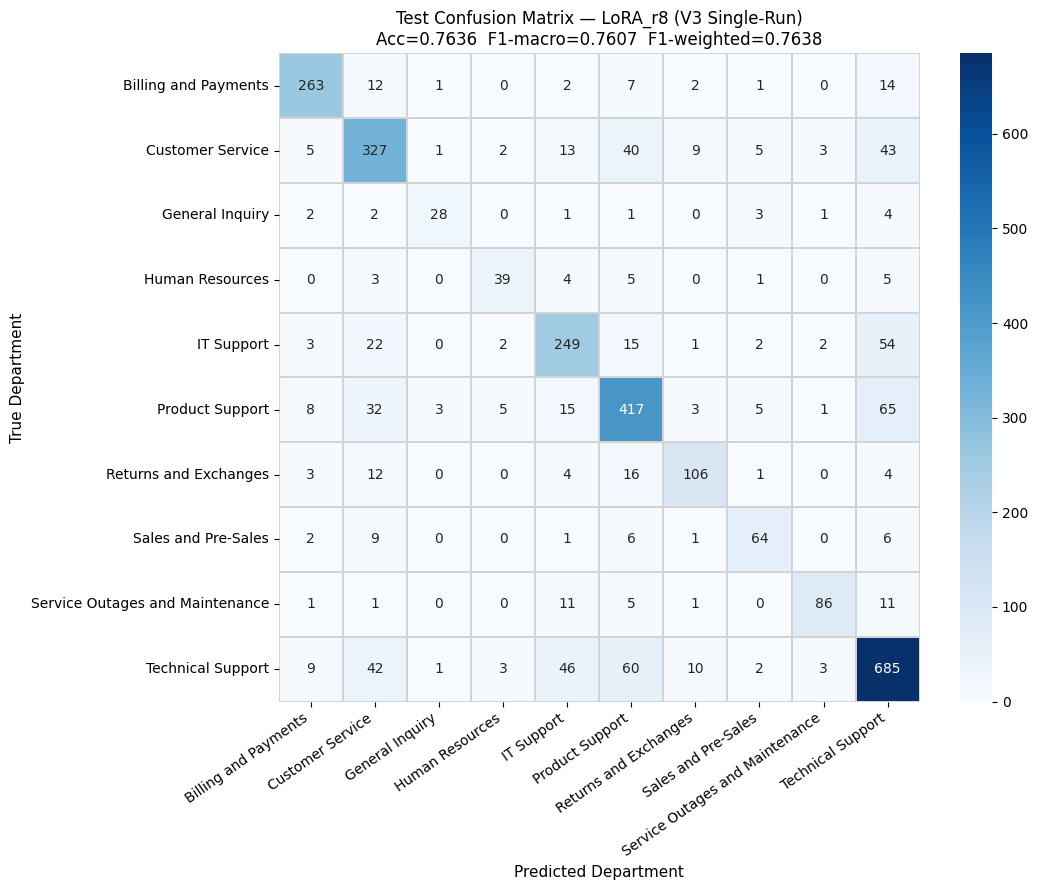


💾 Saved:
   • /content/drive/MyDrive/llama32-ticket-cls-v3-singlerun-r8/LoRA_r8/final_test/test_metrics.json
   • /content/drive/MyDrive/llama32-ticket-cls-v3-singlerun-r8/LoRA_r8/final_test/test_confusion_matrix.png


In [ ]:
# ════════════════════════════════════════════════════════════════════════
# FINAL TEST EVALUATION — LoRA_r8 (V3 Single-Run)
# NOTE: CHECKPOINT_BASE is different for r=8 (separate path)
# ════════════════════════════════════════════════════════════════════════
import gc, json, os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, confusion_matrix
)

# ── IMPORTANT: r=8 uses a DIFFERENT checkpoint base path
CHECKPOINT_BASE = '/content/drive/MyDrive/llama32-ticket-cls-v3-singlerun-r8'

# ── LoRA config for r=8
LORA_CONFIG = {'name': 'LoRA_r8', 'r': 8, 'alpha': 16, 'lr': 2e-4, 'dropout': 0.05}

cfg       = LORA_CONFIG
lora_name = cfg['name']

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

best_dir = os.path.join(CHECKPOINT_BASE, lora_name, 'BEST')
if not os.path.exists(best_dir):
    raise RuntimeError(f'No BEST checkpoint at {best_dir}.')

print(f'🏆 Loading BEST checkpoint from {best_dir}')

# Build model from BEST adapter (frozen — eval only)
test_model = build_model(
    cfg,
    adapter_path=os.path.join(best_dir, 'lora_adapters'),
    is_trainable=False,
)
load_classifier_head(test_model, lora_name, tag='BEST')
test_model.eval()

# ── Run inference manually
all_preds, all_labels = [], []
device = next(test_model.parameters()).device

with torch.no_grad():
    for batch in test_loader:
        input_ids      = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels         = batch['labels'].to(device)
        out    = test_model(input_ids=input_ids, attention_mask=attention_mask)
        logits = out['logits'] if isinstance(out, dict) else out
        preds  = logits.argmax(dim=-1)
        all_preds.extend(preds.cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

# ── Compute metrics
acc   = accuracy_score(all_labels, all_preds)
f1m   = f1_score(all_labels, all_preds, average='macro')
f1w   = f1_score(all_labels, all_preds, average='weighted')
cm    = confusion_matrix(all_labels, all_preds)
report_str  = classification_report(
    all_labels, all_preds,
    target_names=DEPARTMENTS, digits=4, zero_division=0,
)
report_dict = classification_report(
    all_labels, all_preds,
    target_names=DEPARTMENTS, digits=4, zero_division=0, output_dict=True,
)

print('\n' + '=' * 72)
print(f'  FINAL TEST RESULT — {lora_name} (V3 Single-Run)')
print('=' * 72)
print(f'  Accuracy    : {acc:.4f}  ({acc*100:.2f}%)')
print(f'  F1-Macro    : {f1m:.4f}')
print(f'  F1-Weighted : {f1w:.4f}')
print(f'  Test size   : {len(all_labels)}')
print('=' * 72)
print('\nClassification report:\n')
print(report_str)

# ── Save artifacts
final_dir = os.path.join(CHECKPOINT_BASE, lora_name, 'final_test')
os.makedirs(final_dir, exist_ok=True)

# 1) Numbers as JSON
out_json = {
    'config'         : lora_name,
    'strategy'       : 'single_run_full_dataset',
    'test_size'      : len(all_labels),
    'test_accuracy'  : round(float(acc), 6),
    'test_f1_macro'  : round(float(f1m), 6),
    'test_f1_weighted': round(float(f1w), 6),
    'classification_report': report_dict,
    'confusion_matrix': cm.tolist(),
    'class_names'    : DEPARTMENTS,
}
with open(os.path.join(final_dir, 'test_metrics.json'), 'w') as f:
    json.dump(out_json, f, indent=2)

# 2) Confusion matrix PNG
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=DEPARTMENTS, yticklabels=DEPARTMENTS,
    cbar=True, ax=ax, square=False, linewidths=0.3, linecolor='lightgray',
)
ax.set_xlabel('Predicted Department', fontsize=11)
ax.set_ylabel('True Department', fontsize=11)
ax.set_title(f'Test Confusion Matrix — {lora_name} (V3 Single-Run)\n'
             f'Acc={acc:.4f}  F1-macro={f1m:.4f}  F1-weighted={f1w:.4f}',
             fontsize=12)
plt.xticks(rotation=35, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
cm_path = os.path.join(final_dir, 'test_confusion_matrix.png')
plt.savefig(cm_path, dpi=150, bbox_inches='tight')
plt.show()
plt.close()

print(f'\n💾 Saved:')
print(f'   • {os.path.join(final_dir, "test_metrics.json")}')
print(f'   • {cm_path}')

# ── Free memory
del test_model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

**NEEEEEW** LORA 16 training without data lekage


########################################################################
  V3 SINGLE-RUN EXPERIMENT: LoRA_r16
  r=16 | alpha=32 (=2r) | lr=0.0002 | dropout=0.05
  Full training set: 20177 samples (no staging)
########################################################################
==((====))==  Unsloth 2026.5.8: Fast Llama patching. Transformers: 4.57.6.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Unsloth: Dropout = 0 is supported for fast patching. You are using dropout = 0.05.
Unsloth will patch all other layers, except LoRA matrices, causing a performance hit.
Unsloth 2026.5.8 patched 28 layers with 0 QKV layers, 0 O layers and 0 MLP layers.


Loaded fresh rsLoRA adapters for training.
trainable params: 24,313,856 || all params: 3,237,063,680 || trainable%: 0.7511

✅ LlamaTicketClassifier ready
   Hidden size : 3072
   Head        : 3072 → 10  (single linear)
   rsLoRA      : enabled | alpha=32 = 2r
   Pooling     : last non-padding token
   Dropout     : 0.05 (LoRA)
  Scheduler: 1893 total steps (631 per epoch × 3 epochs)

  SINGLE-RUN TRAINING | LoRA_r16
  Train samples: 20177 | Batches: 10089 | Max epochs: 3 | Patience: 2 (global)
  Starting at epoch 1 | best_f1 so far: 0.0000
   Ep1 | Step   500/10089 | Loss:2.5551 | Acc:0.2390 | LR:1.97e-04
   Ep1 | Step  1000/10089 | Loss:2.2789 | Acc:0.2650 | LR:1.93e-04
   Ep1 | Step  1500/10089 | Loss:2.1320 | Acc:0.2893 | LR:1.90e-04
   Ep1 | Step  2000/10089 | Loss:2.0417 | Acc:0.3015 | LR:1.87e-04
   Ep1 | Step  2500/10089 | Loss:1.9829 | Acc:0.3118 | LR:1.84e-04
   Ep1 | Step  3000/10089 | Loss:1.9490 | Acc:0.3218 | LR:1.80e-04
   Ep1 | Step  3500/10089 | Loss:1.9127 | Acc:0.330

/tmp/ipykernel_2000/2135555504.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=f1_pc, y=short, ax=ax2, palette='viridis')


  📊 Saved: /content/drive/MyDrive/llama32-ticket-cls-v3-singlerun-r8/LoRA_r16/Final_Val_(Single-Run).png


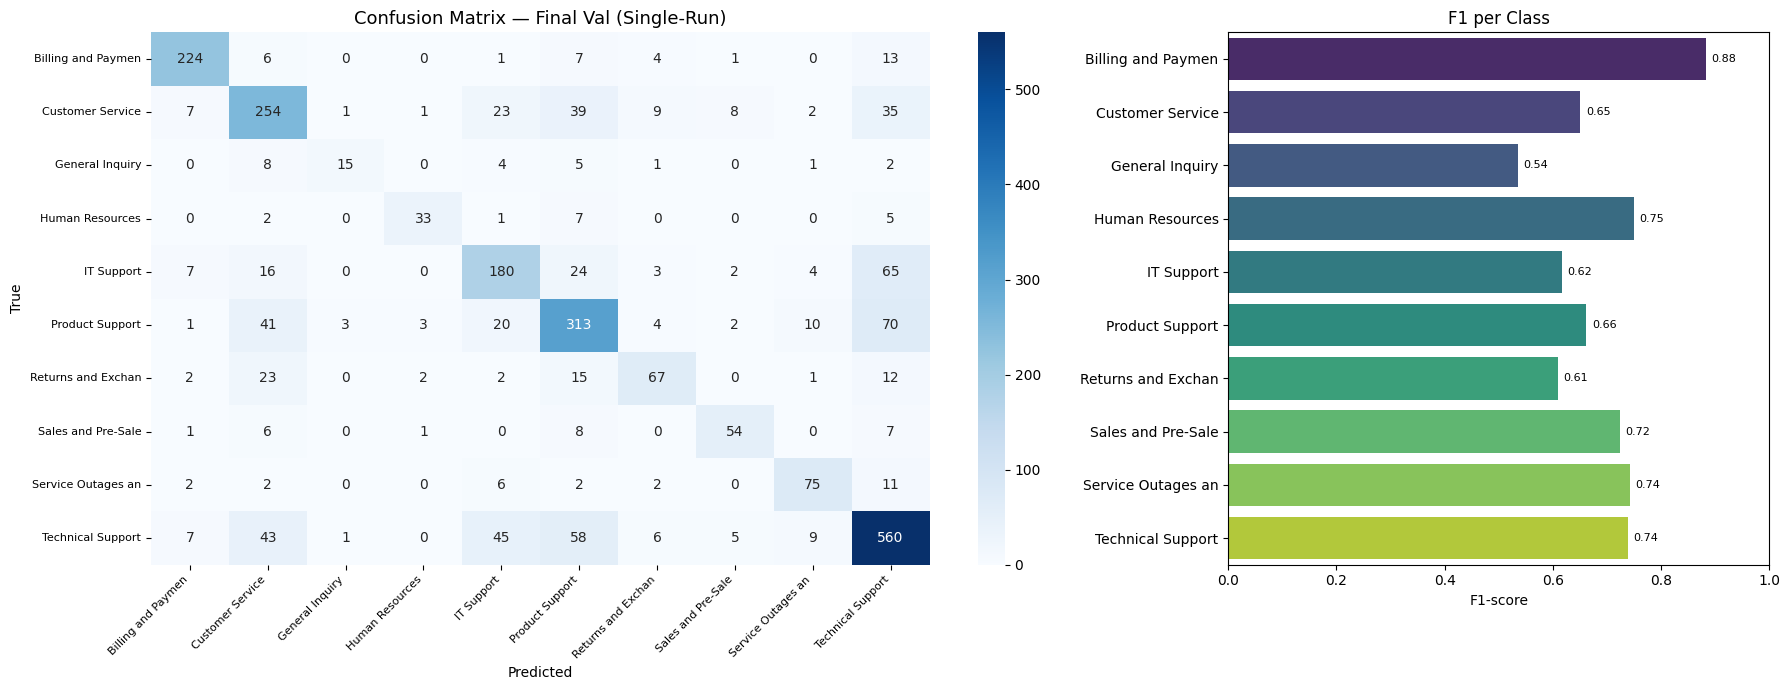


  TRAINING COMPLETE — LoRA_r16 (V3 Single-Run)
  Best Val F1-Macro : 0.6917
  Epochs completed  : 3/3


In [ ]:
# ══════════════════════════════════════════════════
# Fresh start: LoRA_r16 single-run
# ══════════════════════════════════════════════════
gc.collect()
torch.cuda.empty_cache() if torch.cuda.is_available() else None

cfg       = LORA_CONFIG
lora_name = cfg['name']

print()
print('#' * 72)
print(f'  V3 SINGLE-RUN EXPERIMENT: {lora_name}')
print(f'  r={cfg["r"]} | alpha={cfg["alpha"]} (={cfg["alpha"]//cfg["r"]}r) | '
      f'lr={cfg["lr"]} | dropout={cfg["dropout"]}')
print(f'  Full training set: {len(train_df)} samples (no staging)')
print('#' * 72)

model     = build_model(cfg)
trainable = [p for p in model.parameters() if p.requires_grad]

# AdamW8bit — identical to V2
optimizer = bnb.optim.AdamW8bit(
    trainable,
    lr           = cfg['lr'],
    weight_decay = WEIGHT_DECAY,
)

# Global linear scheduler (no warmup) — paper Table 1
scheduler = build_global_scheduler(optimizer)

# Train
best_val_f1, train_history, _ = train_single_run(
    model, optimizer, scheduler, lora_name,
    start_epoch=1, global_best_f1=0.0,
)

# Persist history
summary_dir = os.path.join(CHECKPOINT_BASE, lora_name)
os.makedirs(summary_dir, exist_ok=True)
with open(os.path.join(summary_dir, 'training_history.json'), 'w') as f:
    json.dump(train_history, f, indent=2, default=str)

summary = {
    'config':            lora_name,
    'strategy':          'single_run_full_dataset',
    'r':                 cfg['r'],
    'alpha':             cfg['alpha'],
    'train_samples':     len(train_df),
    'max_epochs':        MAX_EPOCHS,
    'epochs_completed':  len(train_history),
    'best_val_f1_macro': best_val_f1,
}
with open(os.path.join(summary_dir, 'training_summary.json'), 'w') as f:
    json.dump(summary, f, indent=2, default=str)

print()
print('=' * 72)
print(f'  TRAINING COMPLETE — {lora_name} (V3 Single-Run)')
print(f'  Best Val F1-Macro : {best_val_f1:.4f}')
print(f'  Epochs completed  : {len(train_history)}/{MAX_EPOCHS}')
print('=' * 72)

5 h and 15 mins

**NEEEEEW** LORA 16 TEST without data lekage

🏆 Loading BEST checkpoint from:
   /content/drive/MyDrive/llama32-ticket-cls-v3-singlerun-r8/LoRA_r16/BEST

==((====))==  Unsloth 2026.5.8: Fast Llama patching. Transformers: 4.57.6.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Loaded adapters from: /content/drive/MyDrive/llama32-ticket-cls-v3-singlerun-r8/LoRA_r16/BEST/lora_adapters
trainable params: 0 || all params: 3,237,063,680 || trainable%: 0.0000

✅ LlamaTicketClassifier ready
   Hidden size : 3072
   Head        : 3072 → 10  (single linear)
   rsLoRA      : enabled | alpha=32 = 2r
   Pooling     : last non-padding token
   Dropout     : 0.05 (LoRA)
✅ Loaded classifier head: /content/drive/MyDrive/llama3

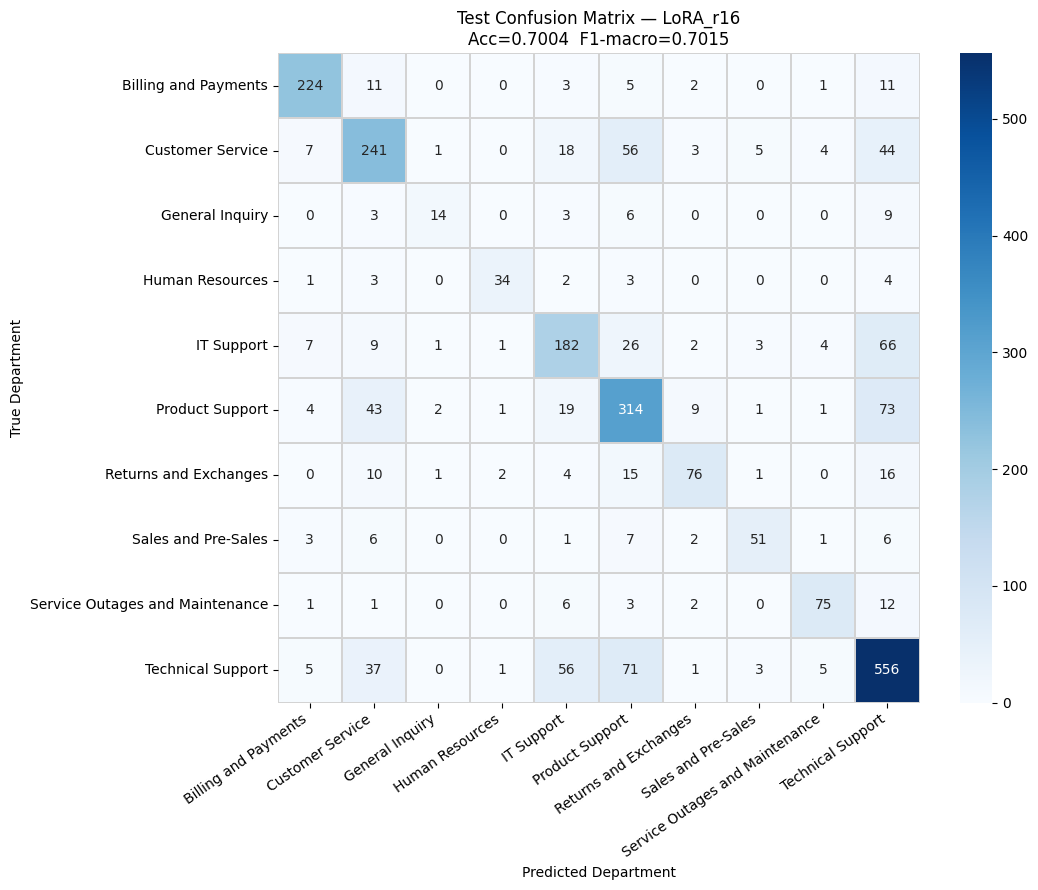


💾 Saved to /content/drive/MyDrive/llama32-ticket-cls-v3-singlerun-r8/LoRA_r16/final_test


In [ ]:
# ════════════════════════════════════════════════════════════════════════
# FINAL TEST EVALUATION — LoRA_r16 (V3 Single-Run, deduplicated)
# ════════════════════════════════════════════════════════════════════════
import gc, json, os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, confusion_matrix
)

# ── MUST match the path training actually wrote to (see training log)
CHECKPOINT_BASE = '/content/drive/MyDrive/llama32-ticket-cls-v3-singlerun-r8'
LORA_CONFIG     = {'name': 'LoRA_r16', 'r': 16, 'alpha': 32, 'lr': 2e-4, 'dropout': 0.05}

cfg       = LORA_CONFIG
lora_name = cfg['name']        # 'LoRA_r16'

gc.collect()
torch.cuda.empty_cache() if torch.cuda.is_available() else None

best_dir = os.path.join(CHECKPOINT_BASE, lora_name, 'BEST')
print(f'🏆 Loading BEST checkpoint from:\n   {best_dir}\n')
if not os.path.exists(best_dir):
    raise RuntimeError(f'No BEST checkpoint at {best_dir}.')

# Build model from the r=16 BEST adapter (frozen — eval only)
test_model = build_model(
    cfg,
    adapter_path=os.path.join(best_dir, 'lora_adapters'),
    is_trainable=False,
)
load_classifier_head(test_model, lora_name, tag='BEST')
test_model.eval()

# ── Inference
all_preds, all_labels = [], []
device = next(test_model.parameters()).device
with torch.no_grad():
    for batch in test_loader:
        input_ids      = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels         = batch['labels'].to(device)
        out    = test_model(input_ids=input_ids, attention_mask=attention_mask)
        logits = out['logits'] if isinstance(out, dict) else out
        all_preds.extend(logits.argmax(dim=-1).cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

acc = accuracy_score(all_labels, all_preds)
f1m = f1_score(all_labels, all_preds, average='macro')
f1w = f1_score(all_labels, all_preds, average='weighted')

print('=' * 72)
print(f'  FINAL TEST RESULT — {lora_name} (deduplicated single-run)')
print('=' * 72)
print(f'  Accuracy    : {acc:.4f}  ({acc*100:.2f}%)')
print(f'  F1-Macro    : {f1m:.4f}')
print(f'  F1-Weighted : {f1w:.4f}')
print(f'  Test size   : {len(all_labels)}')
print('=' * 72)

# ── Sanity guard: test must be near validation (0.6917). Flag mismatch loudly.
EXPECTED_VAL_F1 = 0.6917
if abs(f1m - EXPECTED_VAL_F1) > 0.05:
    print(f'\n⚠️  WARNING: test macro F1 ({f1m:.4f}) is far from validation '
          f'({EXPECTED_VAL_F1:.4f}).')
    print('   This usually means the WRONG checkpoint was loaded, or a data/leakage issue.')
    print('   Do NOT trust this number until the gap is explained.')
else:
    print(f'\n✅ Test ({f1m:.4f}) is consistent with validation ({EXPECTED_VAL_F1:.4f}).')

print('\n' + classification_report(
    all_labels, all_preds, target_names=DEPARTMENTS, digits=4, zero_division=0))

# ── Save
final_dir = os.path.join(CHECKPOINT_BASE, lora_name, 'final_test')
os.makedirs(final_dir, exist_ok=True)
cm = confusion_matrix(all_labels, all_preds)
with open(os.path.join(final_dir, 'test_metrics.json'), 'w') as f:
    json.dump({
        'config': lora_name, 'strategy': 'single_run_dedup',
        'test_size': len(all_labels),
        'test_accuracy': round(float(acc), 6),
        'test_f1_macro': round(float(f1m), 6),
        'test_f1_weighted': round(float(f1w), 6),
        'classification_report': classification_report(
            all_labels, all_preds, target_names=DEPARTMENTS,
            digits=4, zero_division=0, output_dict=True),
        'confusion_matrix': cm.tolist(), 'class_names': DEPARTMENTS,
    }, f, indent=2)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=DEPARTMENTS, yticklabels=DEPARTMENTS,
            cbar=True, ax=ax, linewidths=0.3, linecolor='lightgray')
ax.set_xlabel('Predicted Department'); ax.set_ylabel('True Department')
ax.set_title(f'Test Confusion Matrix — {lora_name}\n'
             f'Acc={acc:.4f}  F1-macro={f1m:.4f}')
plt.xticks(rotation=35, ha='right'); plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(final_dir, 'test_confusion_matrix.png'),
            dpi=150, bbox_inches='tight')
plt.show(); plt.close()
print(f'\n💾 Saved to {final_dir}')

del test_model
gc.collect()
torch.cuda.empty_cache() if torch.cuda.is_available() else None

new clean lora r8 training


########################################################################
  V3 SINGLE-RUN EXPERIMENT: LoRA_8
  r=8 | alpha=16 (=2r) | lr=0.0002 | dropout=0.05
  Full training set: 20177 samples (no staging)
########################################################################
==((====))==  Unsloth 2026.5.9: Fast Llama patching. Transformers: 4.57.6.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Unsloth: Dropout = 0 is supported for fast patching. You are using dropout = 0.05.
Unsloth will patch all other layers, except LoRA matrices, causing a performance hit.
Unsloth 2026.5.9 patched 28 layers with 0 QKV layers, 0 O layers and 0 MLP layers.


Loaded fresh rsLoRA adapters for training.
trainable params: 12,156,928 || all params: 3,224,906,752 || trainable%: 0.3770

✅ LlamaTicketClassifier ready
   Hidden size : 3072
   Head        : 3072 → 10  (single linear)
   rsLoRA      : enabled | alpha=16 = 2r
   Pooling     : last non-padding token
   Dropout     : 0.05 (LoRA)
  Scheduler: 1893 total steps (631 per epoch × 3 epochs)

  SINGLE-RUN TRAINING | LoRA_8
  Train samples: 20177 | Batches: 10089 | Max epochs: 3 | Patience: 2 (global)
  Starting at epoch 1 | best_f1 so far: 0.0000
   Ep1 | Step   500/10089 | Loss:2.4120 | Acc:0.2340 | LR:1.97e-04
   Ep1 | Step  1000/10089 | Loss:2.1621 | Acc:0.2745 | LR:1.93e-04
   Ep1 | Step  1500/10089 | Loss:2.0655 | Acc:0.2873 | LR:1.90e-04
   Ep1 | Step  2000/10089 | Loss:1.9969 | Acc:0.3093 | LR:1.87e-04
   Ep1 | Step  2500/10089 | Loss:1.9481 | Acc:0.3226 | LR:1.84e-04
   Ep1 | Step  3000/10089 | Loss:1.9099 | Acc:0.3322 | LR:1.80e-04
   Ep1 | Step  3500/10089 | Loss:1.8809 | Acc:0.3423 

/tmp/ipykernel_3028/2135555504.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=f1_pc, y=short, ax=ax2, palette='viridis')


  📊 Saved: /content/drive/MyDrive/llama32-ticket-cls-v3-singlerun-r8/LoRA_8/Final_Val_(Single-Run).png


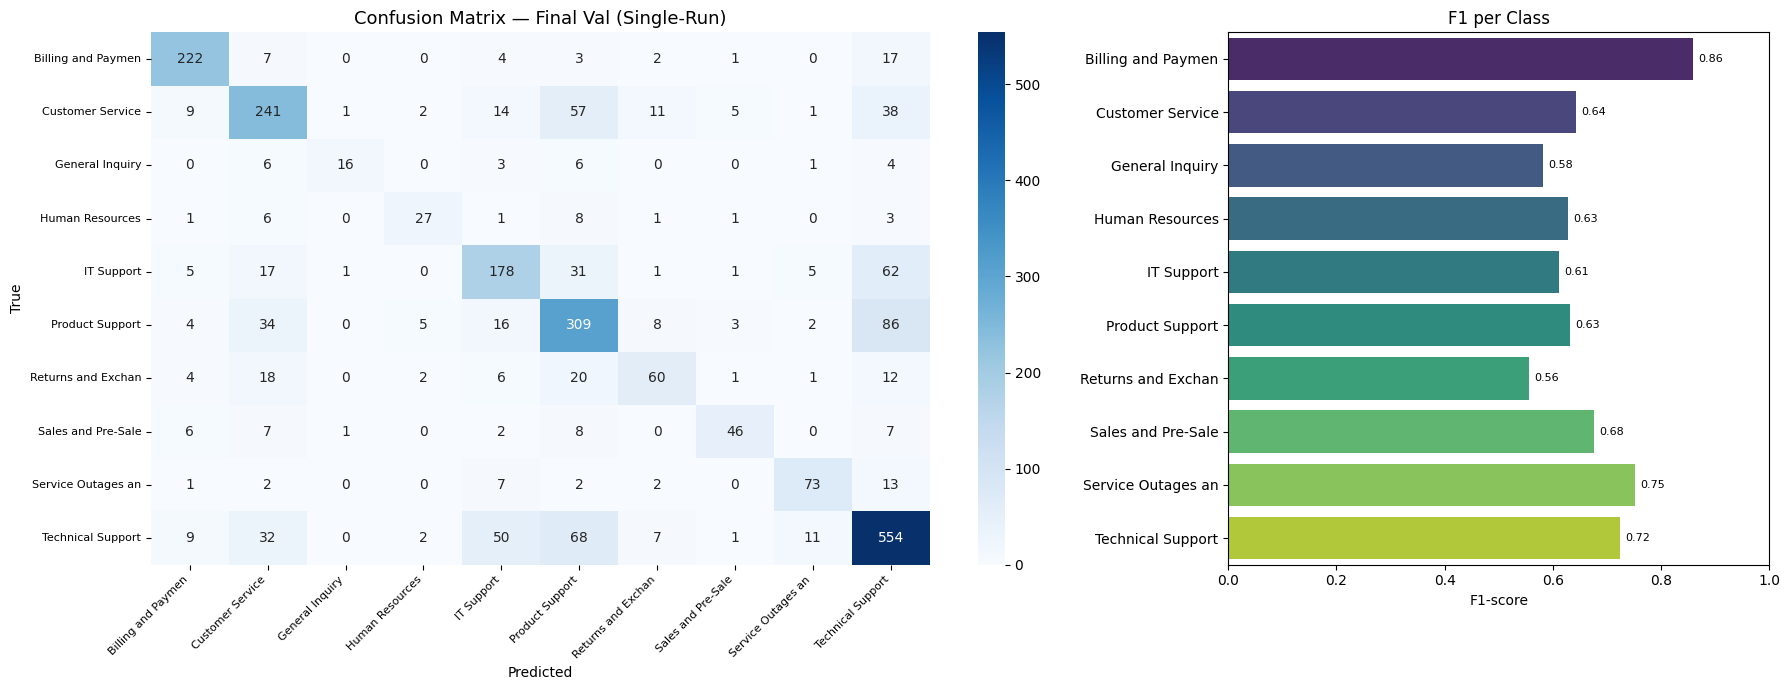


  TRAINING COMPLETE — LoRA_8 (V3 Single-Run)
  Best Val F1-Macro : 0.6664
  Epochs completed  : 3/3


In [ ]:
# ══════════════════════════════════════════════════
# Fresh start: LoRA_r8 single-run
# ══════════════════════════════════════════════════
gc.collect()
torch.cuda.empty_cache() if torch.cuda.is_available() else None

cfg       = LORA_CONFIG
lora_name = cfg['name']

print()
print('#' * 72)
print(f'  V3 SINGLE-RUN EXPERIMENT: {lora_name}')
print(f'  r={cfg["r"]} | alpha={cfg["alpha"]} (={cfg["alpha"]//cfg["r"]}r) | '
      f'lr={cfg["lr"]} | dropout={cfg["dropout"]}')
print(f'  Full training set: {len(train_df)} samples (no staging)')
print('#' * 72)

model     = build_model(cfg)
trainable = [p for p in model.parameters() if p.requires_grad]

# AdamW8bit — identical to V2
optimizer = bnb.optim.AdamW8bit(
    trainable,
    lr           = cfg['lr'],
    weight_decay = WEIGHT_DECAY,
)

# Global linear scheduler (no warmup) — paper Table 1
scheduler = build_global_scheduler(optimizer)

# Train
best_val_f1, train_history, _ = train_single_run(
    model, optimizer, scheduler, lora_name,
    start_epoch=1, global_best_f1=0.0,
)

# Persist history
summary_dir = os.path.join(CHECKPOINT_BASE, lora_name)
os.makedirs(summary_dir, exist_ok=True)
with open(os.path.join(summary_dir, 'training_history.json'), 'w') as f:
    json.dump(train_history, f, indent=2, default=str)

summary = {
    'config':            lora_name,
    'strategy':          'single_run_full_dataset',
    'r':                 cfg['r'],
    'alpha':             cfg['alpha'],
    'train_samples':     len(train_df),
    'max_epochs':        MAX_EPOCHS,
    'epochs_completed':  len(train_history),
    'best_val_f1_macro': best_val_f1,
}
with open(os.path.join(summary_dir, 'training_summary.json'), 'w') as f:
    json.dump(summary, f, indent=2, default=str)

print()
print('=' * 72)
print(f'  TRAINING COMPLETE — {lora_name} (V3 Single-Run)')
print(f'  Best Val F1-Macro : {best_val_f1:.4f}')
print(f'  Epochs completed  : {len(train_history)}/{MAX_EPOCHS}')
print('=' * 72)

4 hours and 45 mins

**NEEEEEW** LORA 8 test without data lekage

FINAL TEST EVALUATION — LoRA_8
🏆 Loading BEST checkpoint from:
   /content/drive/MyDrive/llama32-ticket-cls-v3-singlerun-r8/LoRA_8/BEST

Adapter config check:
  saved r     : 8
  saved alpha : 16
✅ Correct checkpoint: r=8 / alpha=16

BEST validation metrics:
  BEST epoch   : 3
  Val Accuracy : 0.6844
  Val F1-Macro : 0.6664
==((====))==  Unsloth 2026.5.9: Fast Llama patching. Transformers: 4.57.6.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Loaded adapters from: /content/drive/MyDrive/llama32-ticket-cls-v3-singlerun-r8/LoRA_8/BEST/lora_adapters
trainable params: 0 || all params: 3,224,906,752 || trainable%: 0.0000

✅ LlamaTicketClassifier ready
   Hidden size 

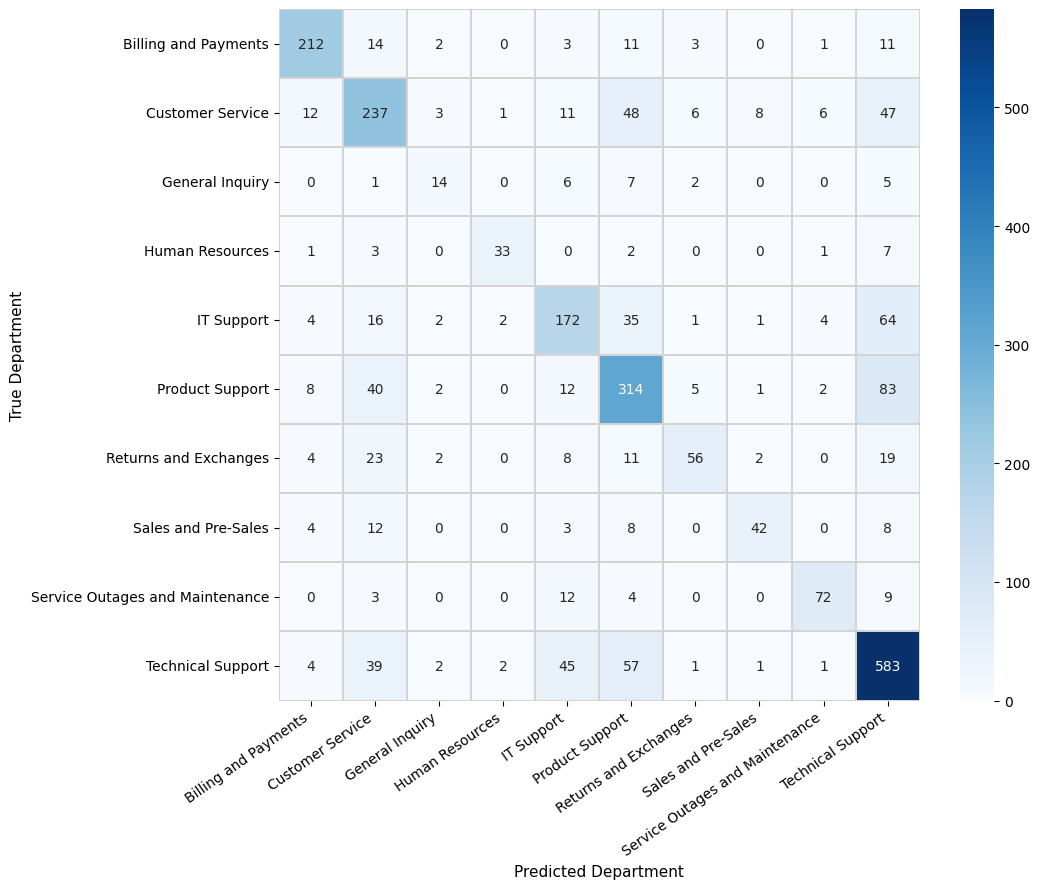


💾 Saved:
   • /content/drive/MyDrive/llama32-ticket-cls-v3-singlerun-r8/LoRA_8/final_test/test_metrics.json
   • /content/drive/MyDrive/llama32-ticket-cls-v3-singlerun-r8/LoRA_8/final_test/test_confusion_matrix.png


In [ ]:
# ════════════════════════════════════════════════════════════════════════
# FINAL TEST EVALUATION — LoRA_8 (V3 Single-Run)
# r=8 | alpha=16
# ════════════════════════════════════════════════════════════════════════

import gc, json, os, torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, confusion_matrix
)

# ── MUST match where training actually saved
CHECKPOINT_BASE = '/content/drive/MyDrive/llama32-ticket-cls-v3-singlerun-r8'

# ── LoRA config for r=8
# IMPORTANT: name must match folder name exactly: LoRA_8
LORA_CONFIG = {
    'name': 'LoRA_8',
    'r': 8,
    'alpha': 16,
    'lr': 2e-4,
    'dropout': 0.05,
}

cfg = LORA_CONFIG
lora_name = cfg['name']

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

best_dir = os.path.join(CHECKPOINT_BASE, lora_name, 'BEST')
adapter_dir = os.path.join(best_dir, 'lora_adapters')
adapter_config_path = os.path.join(adapter_dir, 'adapter_config.json')
head_path = os.path.join(best_dir, 'classifier_head.pt')
metrics_path = os.path.join(best_dir, 'metrics.json')

print('=' * 72)
print(f'FINAL TEST EVALUATION — {lora_name}')
print('=' * 72)
print(f'🏆 Loading BEST checkpoint from:\n   {best_dir}')

if not os.path.exists(best_dir):
    raise RuntimeError(f'No BEST checkpoint at {best_dir}.')

if not os.path.exists(adapter_dir):
    raise RuntimeError(f'No lora_adapters folder at {adapter_dir}.')

if not os.path.exists(adapter_config_path):
    raise RuntimeError(f'No adapter_config.json at {adapter_config_path}.')

if not os.path.exists(head_path):
    raise RuntimeError(f'No classifier_head.pt at {head_path}.')

# ── Confirm adapter config
with open(adapter_config_path, 'r') as f:
    adapter_cfg = json.load(f)

saved_r = int(adapter_cfg.get('r'))
saved_alpha = int(adapter_cfg.get('lora_alpha'))

print('\nAdapter config check:')
print(f'  saved r     : {saved_r}')
print(f'  saved alpha : {saved_alpha}')

if saved_r != cfg['r'] or saved_alpha != cfg['alpha']:
    raise RuntimeError(
        f'Wrong checkpoint loaded. Expected r={cfg["r"]}, alpha={cfg["alpha"]}, '
        f'but found r={saved_r}, alpha={saved_alpha}.'
    )

print('✅ Correct checkpoint: r=8 / alpha=16')

# ── Optional: read validation metrics if available
EXPECTED_VAL_F1 = None

if os.path.exists(metrics_path):
    with open(metrics_path, 'r') as f:
        best_metrics = json.load(f)

    EXPECTED_VAL_F1 = float(best_metrics.get('f1_macro'))
    print('\nBEST validation metrics:')
    print(f'  BEST epoch   : {best_metrics.get("epoch")}')
    print(f'  Val Accuracy : {float(best_metrics.get("accuracy")):.4f}')
    print(f'  Val F1-Macro : {EXPECTED_VAL_F1:.4f}')
else:
    print('\n⚠️ metrics.json not found. Test will run without validation comparison.')

# ── Build model from BEST adapter, frozen — eval only
test_model = build_model(
    cfg,
    adapter_path=adapter_dir,
    is_trainable=False,
)

ok = load_classifier_head(test_model, lora_name, tag='BEST')
if not ok:
    raise RuntimeError(f'Failed to load classifier head from {best_dir}')

test_model.eval()

# ── Run inference manually
all_preds, all_labels = [], []
device = next(test_model.parameters()).device

with torch.no_grad():
    for batch in test_loader:
        input_ids      = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels         = batch['labels'].to(device)

        out = test_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
        )

        logits = out['logits'] if isinstance(out, dict) else out
        preds = logits.argmax(dim=-1)

        all_preds.extend(preds.cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

# ── Compute metrics
acc = accuracy_score(all_labels, all_preds)
f1m = f1_score(all_labels, all_preds, average='macro')
f1w = f1_score(all_labels, all_preds, average='weighted')
cm = confusion_matrix(all_labels, all_preds)

report_str = classification_report(
    all_labels,
    all_preds,
    target_names=DEPARTMENTS,
    digits=4,
    zero_division=0,
)

report_dict = classification_report(
    all_labels,
    all_preds,
    target_names=DEPARTMENTS,
    digits=4,
    zero_division=0,
    output_dict=True,
)

print('\n' + '=' * 72)
print(f'  FINAL TEST RESULT — {lora_name} (V3 Single-Run)')
print('=' * 72)
print(f'  Accuracy    : {acc:.4f}  ({acc*100:.2f}%)')
print(f'  F1-Macro    : {f1m:.4f}')
print(f'  F1-Weighted : {f1w:.4f}')
print(f'  Test size   : {len(all_labels)}')
print('=' * 72)

if EXPECTED_VAL_F1 is not None:
    if abs(f1m - EXPECTED_VAL_F1) > 0.05:
        print(
            f'\n⚠️ WARNING: test macro F1 ({f1m:.4f}) is far from validation '
            f'({EXPECTED_VAL_F1:.4f}).'
        )
        print('   This may mean wrong checkpoint, split mismatch, or a real test/val gap.')
    else:
        print(f'\n✅ Test ({f1m:.4f}) is consistent with validation ({EXPECTED_VAL_F1:.4f}).')

print('\nClassification report:\n')
print(report_str)

# ── Save artifacts
final_dir = os.path.join(CHECKPOINT_BASE, lora_name, 'final_test')
os.makedirs(final_dir, exist_ok=True)

out_json = {
    'config': lora_name,
    'strategy': 'single_run_full_dataset',
    'actual_r': cfg['r'],
    'actual_alpha': cfg['alpha'],
    'adapter_saved_r': saved_r,
    'adapter_saved_alpha': saved_alpha,
    'test_size': len(all_labels),
    'test_accuracy': round(float(acc), 6),
    'test_f1_macro': round(float(f1m), 6),
    'test_f1_weighted': round(float(f1w), 6),
    'classification_report': report_dict,
    'confusion_matrix': cm.tolist(),
    'class_names': DEPARTMENTS,
}

if EXPECTED_VAL_F1 is not None:
    out_json['best_val_f1_macro'] = round(float(EXPECTED_VAL_F1), 6)

metrics_path_out = os.path.join(final_dir, 'test_metrics.json')

with open(metrics_path_out, 'w') as f:
    json.dump(out_json, f, indent=2)

# ── Confusion matrix PNG
fig, ax = plt.subplots(figsize=(11, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=DEPARTMENTS,
    yticklabels=DEPARTMENTS,
    cbar=True,
    ax=ax,
    square=False,
    linewidths=0.3,
    linecolor='lightgray',
)

ax.set_xlabel('Predicted Department', fontsize=11)
ax.set_ylabel('True Department', fontsize=11)


plt.xticks(rotation=35, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

cm_path = os.path.join(final_dir, 'test_confusion_matrix.png')
plt.savefig(cm_path, dpi=150, bbox_inches='tight')
plt.show()
plt.close()

print(f'\n💾 Saved:')
print(f'   • {metrics_path_out}')
print(f'   • {cm_path}')

# ── Free memory
del test_model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()